# 01 — Explore the data

**Goal:** look at real and fake face photos, count how many of each we have, and check the image sizes.
Nothing is trained or saved here.

**Dataset:** Kaggle `xhlulu/140k-real-and-fake-faces` — real faces come from FFHQ, fake faces from StyleGAN.
More details in `docs/03_data.md` in the project.

**Labels:** `fake` = 1 (what we want to catch), `real` = 0.

**How to use:** this notebook runs on **Kaggle** or **Google Colab** (it detects which one by itself). Do the
settings below once, then run the cells from top to bottom (Shift+Enter). No GPU is needed.

### Before you start (Kaggle): settings

Open the right-hand panel of the notebook editor (the **>|** icon at the top right if it is hidden):

- **Settings → Internet → On.** Step 1 downloads the project code from GitHub. Kaggle asks you to verify your phone once.
- **Add Input → Datasets →** search **"140k Real and Fake Faces"** (by xhlulu) → **+**. These are the images.
  Kaggle attaches them read-only under `/kaggle/input/`, so nothing is downloaded or unzipped.

After you change a setting, Kaggle restarts the session: run the cells again from the top.

### Before you start (Google Colab): one-time setup

1. **Open the notebook:** colab.research.google.com → **File → Open notebook → GitHub**, paste
   `https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning` and pick `notebooks/01_explore_data.ipynb`.
2. **Kaggle token (only to download the dataset the first time):** on kaggle.com → **Settings → API → Create New
   Token** downloads `kaggle.json`. Then either add two **Colab Secrets** (key icon on the left):
   `KAGGLE_USERNAME` and `KAGGLE_KEY` with the values from that file and **Notebook access** on, or upload
   `kaggle.json` to your Google Drive at `My Drive/deepfake_kyc/kaggle.json`.
3. Run Step 1. Colab asks to connect your Google Drive: allow it.

**What Step 1 keeps in your Google Drive** (`My Drive/deepfake_kyc/`), so nothing is lost when the session ends:

| In your Drive | What it is |
|---|---|
| `UOT_SCS_3546_041_Deep-Learning/` | the project code; trained models and scores go in its `outputs/` |
| `datasets/140k-real-and-fake-faces.zip` | the dataset zip, downloaded from Kaggle once (about 4 GB) |
| `datasets/140k/` | the unzipped images, only if you choose `DATA_LOCATION = "drive"` |

**Where the images are read from (`DATA_LOCATION` in Step 1):** `"local"` (default) unzips them to Colab's fast
local disk at the start of each session, about 2 minutes; only the zip is stored in Drive. `"drive"` unzips them
into Drive once (the first time can take an hour) and reads them from there, which is much slower, especially
for training. This notebook saves no files of its own.

## Step 1 — Get the project and find the images

**What this does, in plain words:**

1. Loads the Python tools we need and checks whether it runs on Kaggle or Google Colab.
2. Gets the project code (`src/`, `configs/`) from GitHub:
   - **Kaggle:** into `/kaggle/working/`, the only folder on Kaggle where we can write files.
   - **Colab:** connects your Google Drive and keeps the project in `My Drive/deepfake_kyc/`, updating it from
     GitHub at the start (`UPDATE_PROJECT`).
3. Finds the dataset:
   - **Kaggle:** the one you attached with **Add Input**, somewhere under `/kaggle/input/`.
   - **Colab:** downloads the zip into your Drive the first time, then unzips the images (see `DATA_LOCATION`).
4. Counts the images in each folder and prints `Dataset ready.`

The attached dataset has this layout:

```
.../real_vs_fake/real-vs-fake/
├── train/real/*.jpg   train/fake/*.jpg     100,000 photos: the model learns from these
├── valid/real/*.jpg   valid/fake/*.jpg      20,000 photos: used to choose the best model
└── test/real/*.jpg    test/fake/*.jpg       20,000 photos: kept for the final score
```

In [1]:
# 1. Tools we need
import os
import random
import shutil
import subprocess
import sys
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

REPO_URL = "https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning.git"
DATASET = "xhlulu/140k-real-and-fake-faces"     # the Kaggle dataset (about 4 GB zip)

# ---- Google Colab settings (ignored on Kaggle) -------------------------------------------
DRIVE_FOLDER = "deepfake_kyc"   # folder inside "My Drive" for the project, the dataset zip and the outputs
DATA_LOCATION = "local"         # "local" = unzip the images to Colab's fast local disk each session (about 2 min,
                                #           recommended; the zip itself stays on your Drive)
                                # "drive" = unzip once into your Drive (first time can take an hour; reading images
                                #           from Drive is much slower, especially for training)
UPDATE_PROJECT = True           # True = get the latest project code from GitHub at the start (safe: never overwrites
                                #        your own changes, it just prints a message if it cannot update)
# ------------------------------------------------------------------------------------------

ON_KAGGLE = Path("/kaggle/input").is_dir()
ON_COLAB = "google.colab" in sys.modules


def run(command):
    """Run a terminal command and return True if it worked."""
    return subprocess.run(command).returncode == 0


def find_dataset(search_roots):
    """Look inside the given folders for the folder called real-vs-fake that has train/ valid/ test/."""
    for root in search_roots:
        for depth in range(0, 5):                               # look 0, 1, 2, 3, then 4 folders deep
            pattern = "/".join(["*"] * depth + ["real-vs-fake"])  # e.g. "*/*/real-vs-fake"
            for folder in Path(root).glob(pattern):
                if (folder / "train").is_dir():
                    return folder
    return None


def get_kaggle_token(drive_home):
    """Kaggle token for downloading the dataset: Colab Secrets first, then kaggle.json in your Drive folder."""
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return True
    except Exception:
        pass
    token = drive_home / "kaggle.json"
    if token.exists():
        kaggle_dir = Path.home() / ".kaggle"
        kaggle_dir.mkdir(exist_ok=True)
        (kaggle_dir / "kaggle.json").write_bytes(token.read_bytes())
        (kaggle_dir / "kaggle.json").chmod(0o600)
        return True
    return False


if ON_COLAB:
    # 2a. Connect your Google Drive (Colab asks you to allow it the first time).
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_HOME = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    DRIVE_HOME.mkdir(parents=True, exist_ok=True)

    # 2b. The project code lives in your Drive, so it (and everything saved in outputs/) stays after the session ends.
    PROJECT_ROOT = DRIVE_HOME / "UOT_SCS_3546_041_Deep-Learning"
    if not (PROJECT_ROOT / "src").exists():
        print("Downloading the project code into your Drive ...")
        if not run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)]):
            raise RuntimeError("Could not download the project from GitHub. Check the internet connection and run again.")
    elif UPDATE_PROJECT:
        if not run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "-q"]):
            print("Note: could not update the project code (you may have changed files in it). Using the copy in Drive.")

    # 3. The dataset: the zip is downloaded once into your Drive, then unzipped (see DATA_LOCATION above).
    DATASET_ZIP = DRIVE_HOME / "datasets" / "140k-real-and-fake-faces.zip"
    IMAGES_HOME = Path("/content/data") if DATA_LOCATION == "local" else DRIVE_HOME / "datasets" / "140k"
    if find_dataset([IMAGES_HOME]) is None:
        if not DATASET_ZIP.exists():
            if not get_kaggle_token(DRIVE_HOME):
                raise RuntimeError(
                    "To download the dataset once, Colab needs your Kaggle API token. Either add Colab Secrets "
                    "KAGGLE_USERNAME and KAGGLE_KEY (key icon on the left, turn on 'Notebook access'), or put "
                    f"kaggle.json in your Drive folder: My Drive/{DRIVE_FOLDER}/kaggle.json. Then run this cell again.")
            print("Downloading the dataset zip into your Drive (about 4 GB, only the first time) ...")
            DATASET_ZIP.parent.mkdir(parents=True, exist_ok=True)
            if shutil.which("kaggle") is None:
                run([sys.executable, "-m", "pip", "install", "-q", "kaggle"])
            if not run(["kaggle", "datasets", "download", "-d", DATASET, "-p", str(DATASET_ZIP.parent)]):
                raise RuntimeError("Kaggle download failed. Check your Kaggle token, then run this cell again.")
        print(f"Unzipping the images to {IMAGES_HOME} ...")
        IMAGES_HOME.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(DATASET_ZIP) as archive:
            images = [name for name in archive.namelist() if name.startswith("real_vs_fake/")] or archive.namelist()
            archive.extractall(IMAGES_HOME, members=images)
        print(f"Unzipped {len(images):,} files.")
    SEARCH_ROOTS = [IMAGES_HOME]

elif ON_KAGGLE:
    # 2. Get the project code (src/ and configs/) from GitHub into /kaggle/working,
    #    the only folder on Kaggle where we can write files.
    PROJECT_ROOT = Path("/kaggle/working/UOT_SCS_3546_041_Deep-Learning")
    if not PROJECT_ROOT.exists():
        if not run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)]):
            raise RuntimeError("Could not download the project from GitHub. "
                               "Turn on Settings -> Internet in the right-hand panel, then run this cell again.")
    # 3. The dataset you attached with Add Input is somewhere under /kaggle/input.
    SEARCH_ROOTS = [Path("/kaggle/input")]

else:
    # On your own computer: use the project folder this notebook is in, and its data/raw folder.
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "deepfake_kyc").is_dir())
    SEARCH_ROOTS = [PROJECT_ROOT / "data" / "raw"]

sys.path.insert(0, str(PROJECT_ROOT / "src"))   # lets Python import the project's own code
print("Running on:    ", "Google Colab" if ON_COLAB else "Kaggle" if ON_KAGGLE else "this computer")
print("Project folder:", PROJECT_ROOT)

DATA_ROOT = find_dataset(SEARCH_ROOTS)   # folder with train/ valid/ test/, or None if not found
if DATA_ROOT is None:
    print("Dataset not found. On Kaggle: Add Input -> Datasets -> \"140k Real and Fake Faces\", then run this cell again.")
else:
    print("Images folder: ", DATA_ROOT)

SPLITS = ["train", "valid", "test"]
IMAGE_LISTS = {}   # remembers the file list of each folder, so every folder is read only once

def list_images(split, class_name):
    """All .jpg files in one folder, e.g. list_images("train", "fake").

    The first call reads the folder (a few seconds for 50,000 files); after that the list
    is remembered in IMAGE_LISTS and every later call is instant.
    """
    if DATA_ROOT is None:
        return []
    folder = DATA_ROOT / split / class_name
    if folder not in IMAGE_LISTS:
        names = sorted(os.listdir(folder)) if folder.is_dir() else []    # sorting plain names is fast
        IMAGE_LISTS[folder] = [folder / name for name in names if name.lower().endswith(".jpg")]
    return IMAGE_LISTS[folder]

# 4. Read the shared project settings (image size, ...) and count the images.
from deepfake_kyc.config import load_config

cfg = load_config(PROJECT_ROOT / "configs" / "base.yaml")

DATA_AVAILABLE = True
for split in SPLITS:
    n_real, n_fake = len(list_images(split, "real")), len(list_images(split, "fake"))
    print(f"{split:6} real={n_real:,}  fake={n_fake:,}")
    if n_real == 0 or n_fake == 0:
        DATA_AVAILABLE = False      # every split needs both real and fake images
print("Dataset ready." if DATA_AVAILABLE else "Dataset missing: see the message above.")

Cloning into '/kaggle/working/UOT_SCS_3546_041_Deep-Learning'...


Project folder: /kaggle/working/UOT_SCS_3546_041_Deep-Learning
Images folder: /kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake
train  real=50,000  fake=50,000
valid  real=10,000  fake=10,000
test   real=10,000  fake=10,000
Dataset ready.


## Step 2 — Count real and fake images

**What this does:** counts the real and fake images in each split and draws a bar chart.

**Why:** a big difference between the two bars (class imbalance) or an empty folder would be a problem for training.

- `train` teaches the model, `valid` helps choose the best model, `test` is kept for the final score only.

train  total=100,000 | real (0)=50,000 | fake (1)=50,000
valid  total=20,000 | real (0)=10,000 | fake (1)=10,000
test   total=20,000 | real (0)=10,000 | fake (1)=10,000


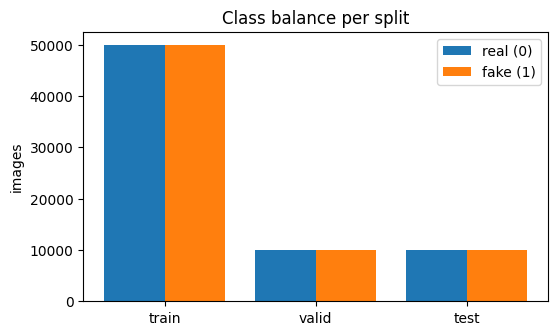

In [2]:
if DATA_AVAILABLE:
    real_counts = [len(list_images(split, "real")) for split in SPLITS]
    fake_counts = [len(list_images(split, "fake")) for split in SPLITS]

    for split, n_real, n_fake in zip(SPLITS, real_counts, fake_counts):
        print(f"{split:6} total={n_real + n_fake:,} | real (0)={n_real:,} | fake (1)={n_fake:,}")

    positions = range(len(SPLITS))
    plt.figure(figsize=(6, 3.5))
    plt.bar([x - 0.2 for x in positions], real_counts, width=0.4, label="real (0)")
    plt.bar([x + 0.2 for x in positions], fake_counts, width=0.4, label="fake (1)")
    plt.xticks(positions, SPLITS)
    plt.ylabel("images")
    plt.title("Class balance per split")
    plt.legend()
    plt.show()
else:
    print("Skipped: dataset not found (Step 1).")

## Step 3 — Check original image sizes

**What this does:** opens 200 random training images and counts their `(width, height)`.

**Why:** the training code resizes every image to one square size (`224×224`) before the model sees it.
It is good to know the original size first. 200 images are enough to see the pattern without opening all 100,000.

In [3]:
if DATA_AVAILABLE:
    random.seed(0)   # same random picks every time you run the cell
    train_images = list_images("train", "real") + list_images("train", "fake")
    sample = random.sample(train_images, min(200, len(train_images)))

    sizes = Counter()
    for path in sample:
        with Image.open(path) as image:
            sizes[image.size] += 1

    print(f"Checked {len(sample)} training images.")
    print("(width, height) -> how many:")
    for size, count in sizes.most_common():
        print(f"  {size}: {count}")
    image_size = cfg["data"]["image_size"]
    print()
    print(f"The training code resizes every image to {image_size}x{image_size}.")
else:
    print("Skipped: dataset not found (Step 1).")

Checked 200 training images.
(width, height) -> how many:
  (256, 256): 200

The training code resizes every image to 224x224.


## Step 4 — Look at a few examples

**What this does:** shows 4 random real and 4 random fake training faces side by side.

**Why:** a quick check for broken files or wrong labels. Fakes are often hard to spot by eye —
that is why we need a model. A few pictures say nothing about how well a model will work.

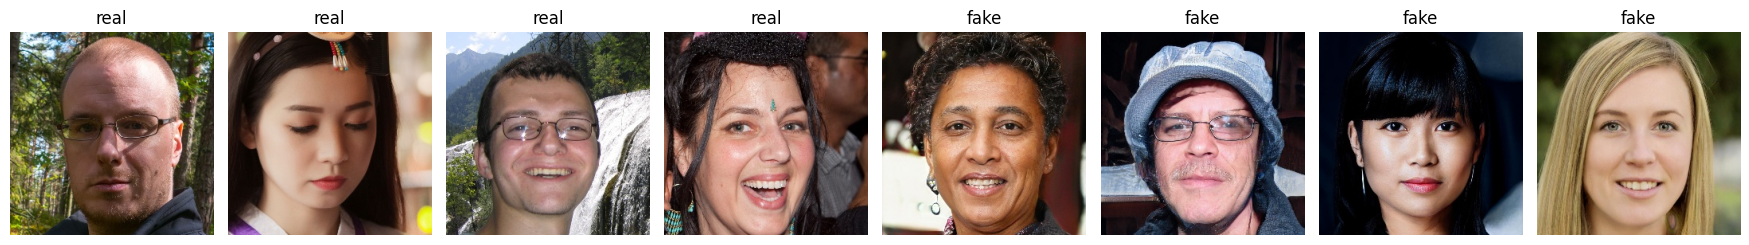

In [4]:
if DATA_AVAILABLE:
    random.seed(0)
    reals = random.sample(list_images("train", "real"), 4)
    fakes = random.sample(list_images("train", "fake"), 4)
    examples = [(path, "real") for path in reals] + [(path, "fake") for path in fakes]

    fig, axes = plt.subplots(1, len(examples), figsize=(2.2 * len(examples), 2.6))
    for ax, (path, label) in zip(axes, examples):
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(label)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: dataset not found (Step 1).")

## Next

Notebook **02_degradations_gallery** shows what these faces look like after the robustness degradations
(blur, JPEG, downscale, noise, screen capture). It attaches the same dataset itself; it does not need this notebook. (Notebooks 02–05 are still set up for Kaggle;
this notebook is the first one that also runs on Google Colab.)

## Quick notes to remember

- `train` teaches the model; `valid` helps choose the model; `test` is held back for the final score.
- `fake = 1` is the positive class and `real = 0` is the negative class.
- The size check looks at only 200 training images, not the whole dataset.
- The example faces are only a sanity check. Do not judge detection accuracy from a few pictures.
- Write the real class counts and image sizes from your run into your report.